In [1]:

import re, numpy as np, nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.probability import FreqDist
for p in ['punkt', 'punkt_tab', 'stopwords', 'wordnet']:
    nltk.download(p, quiet=True)
stop = set(stopwords.words('english'))

i have always loved art 
it feels amazing to get your imagination on a piece of paper 
i get to disconnect from my chaotic routine and dive into my own creative space
in some way or the other every person is an artist just the way of expressing it differs 
for me art does it so well and i always keep coming back to this comfort space of mine
['I have always loved art.', 'It feels amazing to get your imagination on a piece of paper.', 'I get to disconnect from my chaotic routine and dive into my own creative space.', 'In some way or the other, every person is an artist, just the way of expressing it, differs.', 'For me art does it so well and I always keep coming back to this comfort space of mine.']
['i', 'have', 'always', 'loved', 'art', 'it', 'feels', 'amazing', 'to', 'get', 'your', 'imagination', 'on', 'a', 'piece', 'of', 'paper', 'i', 'get', 'to', 'disconnect', 'from', 'my', 'chaotic', 'routine', 'and', 'dive', 'into', 'my', 'own', 'creative', 'space', 'in', 'some', 'way', 'or', 't

<Axes: xlabel='Samples', ylabel='Counts'>

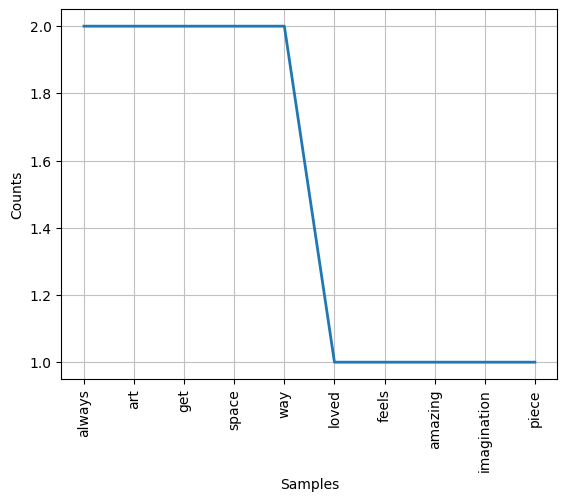

In [2]:
# Q1
text = """I have always loved art.
It feels amazing to get your imagination on a piece of paper.
I get to disconnect from my chaotic routine and dive into my own creative space.
In some way or the other, every person is an artist, just the way of expressing it, differs.
For me art does it so well and I always keep coming back to this comfort space of mine."""

# 1
clean = re.sub(r'[^\w\s]', '', text.lower())
print(clean)

# 2
print(sent_tokenize(text))
words = word_tokenize(clean)
print(words)

# 3
print(text.split())
print(word_tokenize(text))
# split() keeps punctuation stuck to words ("art.", "other,"), word_tokenize() separates punctuation into its own tokens

# 4
filtered = [w for w in words if w not in stop]
print(filtered)

# 5
fd = FreqDist(filtered)
print(fd.most_common())
fd.plot(10)

In [3]:
# Q2
# 1
alpha = re.findall(r'[a-z]+', text.lower())
print(alpha)

# 2
alpha = [w for w in alpha if w not in stop]
print(alpha)

# 3
ps = PorterStemmer()
stemmed = [ps.stem(w) for w in alpha]
print(stemmed)

# 4
wl = WordNetLemmatizer()
lemmatized = [wl.lemmatize(w) for w in alpha]
print(lemmatized)

# 5
for w, s, l in zip(alpha, stemmed, lemmatized):
    print(f"{w:12}{s:12}{l:12}")
# Stemming: fast but crude, can give non-words ("creative" -> "creativ", "always" -> "alway"). Use for search/IR.
# Lemmatization: gives valid dictionary words. Use when meaning matters (sentiment, chatbots).

['i', 'have', 'always', 'loved', 'art', 'it', 'feels', 'amazing', 'to', 'get', 'your', 'imagination', 'on', 'a', 'piece', 'of', 'paper', 'i', 'get', 'to', 'disconnect', 'from', 'my', 'chaotic', 'routine', 'and', 'dive', 'into', 'my', 'own', 'creative', 'space', 'in', 'some', 'way', 'or', 'the', 'other', 'every', 'person', 'is', 'an', 'artist', 'just', 'the', 'way', 'of', 'expressing', 'it', 'differs', 'for', 'me', 'art', 'does', 'it', 'so', 'well', 'and', 'i', 'always', 'keep', 'coming', 'back', 'to', 'this', 'comfort', 'space', 'of', 'mine']
['always', 'loved', 'art', 'feels', 'amazing', 'get', 'imagination', 'piece', 'paper', 'get', 'disconnect', 'chaotic', 'routine', 'dive', 'creative', 'space', 'way', 'every', 'person', 'artist', 'way', 'expressing', 'differs', 'art', 'well', 'always', 'keep', 'coming', 'back', 'comfort', 'space', 'mine']
['alway', 'love', 'art', 'feel', 'amaz', 'get', 'imagin', 'piec', 'paper', 'get', 'disconnect', 'chaotic', 'routin', 'dive', 'creativ', 'space', 

In [4]:
# Q3
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
texts = [
    "India wins the cricket world cup after a thrilling final match",
    "The new smartphone has an amazing camera and a great battery life",
    "Stock market falls sharply as inflation worries investors across the world"
]

# 1
cv = CountVectorizer()
bow = cv.fit_transform(texts)
print(cv.get_feature_names_out())
print(bow.toarray())

# 2
tv = TfidfVectorizer()
tfidf = tv.fit_transform(texts)
features = tv.get_feature_names_out()
print(np.round(tfidf.toarray(), 2))

# 3
for i, row in enumerate(tfidf.toarray()):
    top = row.argsort()[-3:][::-1]
    print(f"Text {i+1}:", [(features[j], round(row[j], 3)) for j in top])
# High TF-IDF = word is frequent in that text but rare in the others, so it best describes that text

['across' 'after' 'amazing' 'an' 'and' 'as' 'battery' 'camera' 'cricket'
 'cup' 'falls' 'final' 'great' 'has' 'india' 'inflation' 'investors'
 'life' 'market' 'match' 'new' 'sharply' 'smartphone' 'stock' 'the'
 'thrilling' 'wins' 'world' 'worries']
[[0 1 0 0 0 0 0 0 1 1 0 1 0 0 1 0 0 0 0 1 0 0 0 0 1 1 1 1 0]
 [0 0 1 1 1 0 1 1 0 0 0 0 1 1 0 0 0 1 0 0 1 0 1 0 1 0 0 0 0]
 [1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 1 1 0 1 0 0 1 0 1 1 0 0 1 1]]
[[0.   0.33 0.   0.   0.   0.   0.   0.   0.33 0.33 0.   0.33 0.   0.
  0.33 0.   0.   0.   0.   0.33 0.   0.   0.   0.   0.2  0.33 0.33 0.25
  0.  ]
 [0.   0.   0.31 0.31 0.31 0.   0.31 0.31 0.   0.   0.   0.   0.31 0.31
  0.   0.   0.   0.31 0.   0.   0.31 0.   0.31 0.   0.18 0.   0.   0.
  0.  ]
 [0.32 0.   0.   0.   0.   0.32 0.   0.   0.   0.   0.32 0.   0.   0.
  0.   0.32 0.32 0.   0.32 0.   0.   0.32 0.   0.32 0.19 0.   0.   0.24
  0.32]]
Text 1: [('wins', np.float64(0.335)), ('thrilling', np.float64(0.335)), ('match', np.float64(0.335))]
Text 2: [('sma

In [5]:
# Q4
from sklearn.metrics.pairwise import cosine_similarity
t1 = "Artificial intelligence enables machines to learn from data and make decisions. It is used in healthcare, robotics and finance. Machine learning models improve with more data."
t2 = "Blockchain is a decentralized ledger that records transactions securely. It is used in cryptocurrency and finance. Data stored in blocks cannot be easily changed."

# 1
def prep(t):
    t = re.sub(r'[^\w\s]', '', t.lower())
    return [w for w in word_tokenize(t) if w not in stop]
tok1, tok2 = prep(t1), prep(t2)
print(tok1, tok2)

# 2a
s1, s2 = set(tok1), set(tok2)
print("Jaccard:", len(s1 & s2) / len(s1 | s2))

# 2b
mat = TfidfVectorizer(stop_words='english').fit_transform([t1, t2])
print("Cosine:", cosine_similarity(mat[0], mat[1])[0][0])

# 2c
# Jaccard only checks word overlap, ignores frequency/importance.
# Cosine on TF-IDF weighs important words, so it gives better insight here.
# Both low = the two technologies are different, which is correct.

['artificial', 'intelligence', 'enables', 'machines', 'learn', 'data', 'make', 'decisions', 'used', 'healthcare', 'robotics', 'finance', 'machine', 'learning', 'models', 'improve', 'data'] ['blockchain', 'decentralized', 'ledger', 'records', 'transactions', 'securely', 'used', 'cryptocurrency', 'finance', 'data', 'stored', 'blocks', 'easily', 'changed']
Jaccard: 0.1111111111111111
Cosine: 0.14291303433897698


Positive  pol=0.52 sub=0.77 | This phone is amazing, the camera is excellent and battery lasts long
Negative  pol=-0.65 sub=0.80 | Worst service ever, the delivery was late and the product was damaged
Positive  pol=0.43 sub=0.54 | The product is okay, nothing special
Positive  pol=0.46 sub=0.65 | Absolutely love this laptop, super fast and great display
Negative  pol=-1.00 sub=1.00 | Terrible quality, stopped working after two days
Positive  pol=0.61 sub=0.80 | Good value for money and very comfortable to use


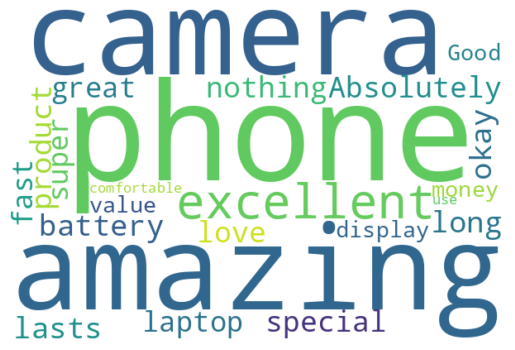

In [6]:
# Q5
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "This phone is amazing, the camera is excellent and battery lasts long",
    "Worst service ever, the delivery was late and the product was damaged",
    "The product is okay, nothing special",
    "Absolutely love this laptop, super fast and great display",
    "Terrible quality, stopped working after two days",
    "Good value for money and very comfortable to use"
]

# 1 and 2
pos_reviews = []
for r in reviews:
    pol, sub = TextBlob(r).sentiment
    label = "Positive" if pol > 0.1 else "Negative" if pol < -0.1 else "Neutral"
    if label == "Positive":
        pos_reviews.append(r)
    print(f"{label:9} pol={pol:.2f} sub={sub:.2f} | {r}")

# 3
wc = WordCloud(width=600, height=400, background_color='white').generate(" ".join(pos_reviews))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()

In [7]:
# Q6
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical

data = text

# 1
tokenizer = Tokenizer()
tokenizer.fit_on_texts([data])
total_words = len(tokenizer.word_index) + 1

# 2
sequences = []
for line in data.split('.'):
    seq = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(seq)):
        sequences.append(seq[:i + 1])
max_len = max(len(s) for s in sequences)
sequences = pad_sequences(sequences, maxlen=max_len, padding='pre')
X, y = sequences[:, :-1], to_categorical(sequences[:, -1], num_classes=total_words)

model = Sequential([
    Embedding(total_words, 32),
    LSTM(64),
    Dense(total_words, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# 3
model.fit(X, y, epochs=300, verbose=0)

def generate(seed, n=8):
    for _ in range(n):
        seq = pad_sequences(tokenizer.texts_to_sequences([seed]), maxlen=max_len - 1, padding='pre')
        pred = np.argmax(model.predict(seq, verbose=0), axis=-1)[0]
        seed += ' ' + tokenizer.index_word.get(pred, '')
    return seed

for s in ["art", "i", "every"]:
    print(generate(s))

art me art does it so well and i
i have always loved art art art well and
every me art does it so well and i
